In [1]:
import h5py

In [2]:
import sys
print(sys.path)

['C:\\Users\\olesk\\repos\\ECM_cell_cycle_model\\umap_window', 'C:\\Users\\olesk\\anaconda3\\envs\\cellxgene\\python39.zip', 'C:\\Users\\olesk\\anaconda3\\envs\\cellxgene\\DLLs', 'C:\\Users\\olesk\\anaconda3\\envs\\cellxgene\\lib', 'C:\\Users\\olesk\\anaconda3\\envs\\cellxgene', '', 'C:\\Users\\olesk\\anaconda3\\envs\\cellxgene\\lib\\site-packages', 'C:\\Users\\olesk\\anaconda3\\envs\\cellxgene\\lib\\site-packages\\win32', 'C:\\Users\\olesk\\anaconda3\\envs\\cellxgene\\lib\\site-packages\\win32\\lib', 'C:\\Users\\olesk\\anaconda3\\envs\\cellxgene\\lib\\site-packages\\Pythonwin']


In [3]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import joblib
import anndata as ad
from scipy.signal import find_peaks
import h5py

In [4]:
prot = joblib.load("C:\\Users\\olesk\\data\\all_prot_1026.sav")

In [5]:
len_prot = int(prot.shape[0]/6)
win_len = int(prot.shape[1]/18)

In [8]:
prot_ab = prot[:, 20::40]

In [9]:
type(prot_ab)

numpy.ndarray

In [12]:
prot

array([[0.24489796, 0.24489796, 0.24489796, ..., 0.08      , 0.085     ,
        0.095     ],
       [0.26530612, 0.28571429, 0.28571429, ..., 0.1       , 0.08      ,
        0.075     ],
       [0.28571429, 0.28571429, 0.26530612, ..., 0.095     , 0.08      ,
        0.105     ],
       ...,
       [0.32653061, 0.30612245, 0.30612245, ..., 0.1       , 0.085     ,
        0.075     ],
       [0.26530612, 0.24489796, 0.2244898 , ..., 0.08      , 0.085     ,
        0.07      ],
       [0.24489796, 0.2244898 , 0.2244898 , ..., 0.06      , 0.055     ,
        0.055     ]])

In [156]:
prot.shape

(239958, 720)

In [13]:
umap_embed = joblib.load("C:\\Users\\olesk\\data\\embedding_1026.sav")

In [14]:
umap_embed.shape

(239958, 2)

In [160]:
adata = ad.AnnData(prot)

In [161]:
adata.obs_names = [f"win_{i:d}" for i in range(adata.n_obs)]

In [163]:
prot_names = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]

all_names = []
for name in prot_names:
    tmp_name = [f"{name}_{i:d}" for i in range(win_len)]
    all_names = all_names + tmp_name
adata.var_names = all_names

In [35]:
dt = ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot
adata.obs["drug"] = pd.Categorical(dt)

In [36]:
st = [0.2]*len_prot*2 + [4]*len_prot*2 + [55]*len_prot*2
adata.obs["stiffness"] = pd.Categorical(st)

In [37]:
adata.obsm["X_umap"] = umap_embed

In [24]:
def getIMTab(prot):
    peaks_E, _ = find_peaks(prot[:,11], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(prot[:,17], prominence = 40/200, distance = 10)
    
    time_st = 0.1
    
    tmp = np.empty((peaks_E[3],1))
    tmp[:] = np.nan
    div_time = pd.DataFrame(tmp)
    
    for n in range(3,len(peaks_E)-3):   #make sure we have divisions at ends 
        tmp_g1_s = peaks_E[n]
        tmp_g1_s_2 = peaks_E[n+1]
        tmp_g1_s_3 = peaks_E[n+2]  
        
        tmp_mit = peaks_cdc[(tmp_g1_s < peaks_cdc) & (peaks_cdc < tmp_g1_s_2)]
        tmp_mit2 = peaks_cdc[(tmp_g1_s_2 < peaks_cdc) & (peaks_cdc < tmp_g1_s_3)]
          
             
        if (np.size(tmp_mit) > 0) & (np.size(tmp_mit2)>0):
            ordered = [tmp_g1_s, tmp_mit[0], tmp_g1_s_2, tmp_mit2[0], tmp_g1_s_3]
            g1_len_tmp = np.array([ordered[2]*time_st]) - np.array([ordered[1]*time_st])
            tmp = [g1_len_tmp]*int(ordered[2]-ordered[0])
            tmp = np.concatenate(tmp, axis=0)
            tmp_df = pd.DataFrame(tmp)

            div_time = pd.concat([div_time, tmp_df], ignore_index=True)
        else:
            tmp = np.empty((int(peaks_E[n+1]-peaks_E[n]),1))
            tmp[:] = np.nan
            tmp_df = pd.DataFrame(tmp)
            div_time = pd.concat([div_time, tmp_df], ignore_index=True) 
    
    tmp = np.empty((len(prot)-peaks_E[-3],1))
    tmp[:] = np.nan
    tmp_df = pd.DataFrame(tmp)
    div_time = pd.concat([div_time, tmp_df], ignore_index=True) 
    
    return div_time

In [25]:
def getIMT(prot):
    peaks_E, _ = find_peaks(prot[:,int((win_len*11+win_len/2)-1)], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(prot[:,int((win_len*17+win_len/2)-1)], prominence = 40/200, distance = 10)
    
    time_st = 0.1
    
    tmp = np.empty((peaks_E[3],1))
    tmp[:] = np.nan
    div_time = pd.DataFrame(tmp)
    
    for n in range(3,len(peaks_E)-3):   #make sure we have divisions at ends 
        tmp_g1_s = peaks_E[n]
        tmp_g1_s_2 = peaks_E[n+1]
        tmp_g1_s_3 = peaks_E[n+2]  
        
        tmp_mit = peaks_cdc[(tmp_g1_s < peaks_cdc) & (peaks_cdc < tmp_g1_s_2)]
        tmp_mit2 = peaks_cdc[(tmp_g1_s_2 < peaks_cdc) & (peaks_cdc < tmp_g1_s_3)]
          
             
        if (np.size(tmp_mit) > 0) & (np.size(tmp_mit2)>0):
            ordered = [tmp_g1_s, tmp_mit[0], tmp_g1_s_2, tmp_mit2[0], tmp_g1_s_3]
            g1_len_tmp = np.array([ordered[2]*time_st]) - np.array([ordered[1]*time_st])
            tmp = [g1_len_tmp]*int(ordered[2]-ordered[0])
            tmp = np.concatenate(tmp, axis=0)
            tmp_df = pd.DataFrame(tmp)

            div_time = pd.concat([div_time, tmp_df], ignore_index=True)
        else:
            tmp = np.empty((int(peaks_E[n+1]-peaks_E[n]),1))
            tmp[:] = np.nan
            tmp_df = pd.DataFrame(tmp)
            div_time = pd.concat([div_time, tmp_df], ignore_index=True) 
    
    tmp = np.empty((len(prot)-peaks_E[-3],1))
    tmp[:] = np.nan
    tmp_df = pd.DataFrame(tmp)
    div_time = pd.concat([div_time, tmp_df], ignore_index=True) 
    
    return div_time

In [138]:
all_divs = []
for num in range(6):
    tmp_div = getIMT(prot[num*len_prot:(num+1)*len_prot,:])
    tmp_list = tmp_div[0].values.tolist()
    all_divs = all_divs + tmp_list
    print(num)

0
1
2
3
4
5


In [139]:
G1_cats = []
for val in all_divs:
    if val <= 15:
        tmp = 'Short'
    elif (val > 15) & (val <= 25):
        tmp = 'Int'
    elif val > 25:
        tmp = 'Long'
    else:
        tmp = 'nan'
    
    G1_cats.append(tmp)

In [135]:
len(G1_cats)

39993

In [137]:
G1_cats[5000]

'Short'

In [140]:
adata.obs["G1_time"] = pd.Categorical(G1_cats)

In [141]:
adata.write('orig_params_all.h5ad')

In [15]:
prot_ab = prot[:, 20::40]

In [41]:
min(prot_ab[:,10])

0.004901960784313725

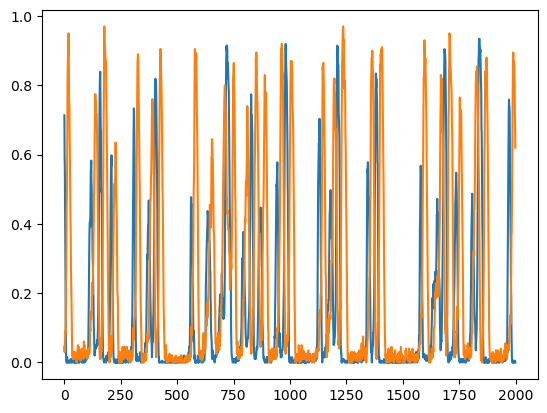

In [44]:
plt.plot(prot_ab[:2000,11])
plt.plot(prot_ab[:2000,17])

In [18]:
adata = ad.AnnData(prot_ab)

adata.obs_names = [f"win_{i:d}" for i in range(adata.n_obs)]

prot_names = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]

adata.var_names = prot_names

In [45]:
adata.obs_names

Index(['win_0', 'win_1', 'win_2', 'win_3', 'win_4', 'win_5', 'win_6', 'win_7',
       'win_8', 'win_9',
       ...
       'win_239948', 'win_239949', 'win_239950', 'win_239951', 'win_239952',
       'win_239953', 'win_239954', 'win_239955', 'win_239956', 'win_239957'],
      dtype='object', length=239958)

In [22]:
dt = ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot
adata.obs["drug"] = pd.Categorical(dt)

st = [0.2]*len_prot*2 + [4]*len_prot*2 + [55]*len_prot*2
adata.obs["stiffness"] = pd.Categorical(st)

adata.obsm["X_umap"] = umap_embed

In [26]:
all_divs = []
for num in range(6):
    tmp_div = getIMTab(prot_ab[num*len_prot:(num+1)*len_prot,:])
    tmp_list = tmp_div[0].values.tolist()
    all_divs = all_divs + tmp_list
    print(num)

0
1
2
3
4
5


In [27]:
G1_cats = []
for val in all_divs:
    if val <= 10:
        tmp = 'Short'
    elif (val > 10) & (val <= 20):
        tmp = 'Int'
    elif val > 20:
        tmp = 'Long'
    else:
        tmp = 'nan'
    
    G1_cats.append(tmp)

In [28]:
adata.obs["G1_time"] = pd.Categorical(G1_cats)

adata.write('orig_params_all_ab.h5ad')